# Exploration theta reco
- Plots of theta reco against theta true in each energy bin ? 


In [1]:
import ROOT, glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.dpi'] = 400
plt.rcParams['savefig.dpi'] = 400

cling::DynamicLibraryManager::loadLibrary(): libOpenGL.so.0: cannot open shared object file: No such file or directory
Error in <AutoloadLibraryMU>: Failed to load library /cvmfs/sft.cern.ch/lcg/releases/ROOT/6.28.04-740f6/x86_64-el9-gcc11-opt/lib/libEve.socling JIT session error: Failed to materialize symbols: { (main, { _ZeqRK7TStringRKNSt7__cxx1112basic_stringIcSt11char_traitsIcESaIcEEE }) }


Welcome to JupyROOT 6.28/04


In [2]:
def browse_files(filenames):
    """
    Browse through the list of filenames and return a sorted list of files.
    """
    if isinstance(filenames, str):
        files = sorted(glob.glob(filenames))
    elif isinstance(filenames, list):
        files = []
        for filename in filenames:
            files += sorted(glob.glob(filename))
    else:
        raise ValueError("Input should be a string or a list of strings.")
    
    return files


### Load data

In [3]:
dirDir= "/home/users/l/lebrun/"
dataDir = "/dpnc/beegfs/dampe/tryf/MC_Skimmed/MC_gamma/"
figPath_ = dirDir + "figures/"
resultPath = dirDir + "results/"
dataPath1 = dirDir + "data/"
dataPath2 = "/dpnc/beegfs/dampe/tryf/ForKimberly/"

exponent = 0

figPath = figPath_+f"explo/thetaReco/"
# file = dataPath + f"MC_exp{exponent:.1f}.root"

dataPath_scaled = dataPath2 + "tt_scaled" + "_cos_theta_bins/"
dataPath_scaled += f"exp{exponent:.1f}/"

files_scaled = browse_files(dataPath_scaled + "*.root")

dataPath_filtered = dataPath2 + "tt_filtered" + "_cos_theta_bins/"
dataPath_filtered += f"exp{exponent:.1f}/"
print(f"dataPath_filtered: {dataPath_filtered}")

files_filtered = browse_files(dataPath_filtered + "*.root")

# Pass the list of files to RDataFrame
# DmlNtup
print(f"Loading files: {files_scaled}")
rdf = ROOT.RDataFrame("MC", files_scaled)

print(f"Loading files: {files_filtered}")
rdf_filtered = ROOT.RDataFrame("MC", files_filtered)
rdf_filtered = rdf_filtered.Filter("tt_isHET == 1")

# # Apply cut on FoV
# rdf = rdf.Filter("theta_True < 60")


dataPath_filtered: /dpnc/beegfs/dampe/tryf/ForKimberly/tt_filtered_cos_theta_bins/exp0.0/
Loading files: ['/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_0.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_1.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_10.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_11.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_12.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_13.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_14.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_15.root', '/dpnc/beegfs/dampe/tryf/ForKimberly/tt_scaled_cos_theta_bins/exp0.0/scaled_costheta_bin_16.root', '/dpn

In [4]:
# Extract only desired columns

df = rdf.AsNumpy(["E_true", "weight", "tt_theta", "theta_BestSTK", 'tt_bgoTotalEcorr_GeV', 'tt_phi'])
df = pd.DataFrame(df)
print("Number of entries in original : ", len(df))

Number of entries in original :  39414874


In [5]:
print(f"Number of tt_theta outliers : {len(df[(df['tt_theta'] > np.pi) | (df['tt_theta'] < -np.pi)])}")
df = df.loc[(df['tt_theta'] < np.pi) & (df['tt_theta'] > -np.pi)]

Number of tt_theta outliers : 0


In [6]:
print(f"Number of correct thetas : {len(df)}")

Number of correct thetas : 39414874


### Necessary transformations

In [7]:
# Print min max of E_true
print(f"Minimum E_true: {df['E_true'].min()} GeV")
print(f"Maximum E_true: {df['E_true'].max()} GeV")
df = df.rename(columns={'tt_theta' : 'theta_True'})
print(f"Minimum theta_True: {df['theta_True'].min()} rad")
print(f"Maximum theta_True: {df['theta_True'].max()} rad")
print(f"Minimum theta_BestSTK: {df['theta_BestSTK'].min()} deg")
print(f"Maximum theta_BestSTK: {df['theta_BestSTK'].max()} deg")
df['theta_True_deg']= np.rad2deg(df['theta_True'])
print(f"Minimum theta_True: {df['theta_True_deg'].min()} degrees")
print(f"Maximum theta_True: {df['theta_True_deg'].max()} degrees")

df['cosTheta'] = np.cos(df['theta_True'])

print(f"Minimum cos Theta : {df['cosTheta'].min()}")
print(f"Maximum cos Theta : {df['cosTheta'].max()}")

df['cosThetaSTK'] = np.cos(np.deg2rad(df['theta_BestSTK']))

df['E_reco'] = df["tt_bgoTotalEcorr_GeV"]

Minimum E_true: 1.0000000821673125 GeV
Maximum E_true: 9999.997300585635 GeV
Minimum theta_True: 0.00017954504136443578 rad
Maximum theta_True: 1.5707963025216998 rad
Minimum theta_BestSTK: 2.53553573e-315 deg
Maximum theta_BestSTK: 86.29922589728199 deg
Minimum theta_True: 0.010287173102683957 degrees
Maximum theta_True: 89.99999860924827 degrees
Minimum cos Theta : 2.42731968471168e-08
Maximum cos Theta : 0.9999999838817891


In [8]:
# Load filtered data here
dfHET = rdf_filtered.AsNumpy(["weight", "tt_theta", "tt_isHET", "tt_ekin", "theta_BestSTK", "tt_bgoTotalEcorr_GeV", "tt_phi", "phi_BestSTK"])
dfHET = pd.DataFrame(dfHET)

dfHET = dfHET.rename(columns={'tt_theta' : 'theta_True'})

# Print number of events
# Print number of event in df
print(f"Number of events in original data: {len(df)}")
print(f"Number of events in filtered data: {len(dfHET)}")

print(f"Minimum theta_True: {dfHET['theta_True'].min()} rad")
print(f"Maximum theta_True: {dfHET['theta_True'].max()} rad")
print(f"Minimum theta_BestSTK: {dfHET['theta_BestSTK'].min()} deg")
print(f"Maximum theta_BestSTK: {dfHET['theta_BestSTK'].max()} deg")
# Filter the DataFrame to keep only HET events
dfHET = dfHET[dfHET['tt_isHET'] == 1]
# Print number of HET events
print(f"Number of HET events: {len(dfHET)}")
# Add energy column in GeV
# TODO : assess and change / remove
dfHET['E_true'] = dfHET['tt_ekin'] * 1e-3 # Convert tt_ekin from MeV to GeV
dfHET['E_reco'] = dfHET["tt_bgoTotalEcorr_GeV"]
# Print min max of E_true
print(f"Minimum E_true: {dfHET['E_true'].min()} GeV")
print(f"Maximum E_true: {dfHET['E_true'].max()} GeV")

dfHET = dfHET[dfHET['E_true'] <= 1e4]
print(f"Number of HET events with E_true <= 10 TeV: {len(dfHET)}")

dfHET['theta_True_deg']= np.rad2deg(dfHET['theta_True'])
# dfHET['theta_True'] = np.deg2rad(dfHET['theta_True'])
dfHET['cosTheta'] = np.cos(dfHET['theta_True'])

dfHET['cosThetaSTK'] = np.cos(np.deg2rad(dfHET['theta_BestSTK']))


print(f"Minimum theta_True: {dfHET['theta_True_deg'].min()} degrees")
print(f"Maximum theta_True: {dfHET['theta_True_deg'].max()} degrees")

Number of events in original data: 39414874
Number of events in filtered data: 175751
Minimum theta_True: 0.0014336268100510286 rad
Maximum theta_True: 1.5621901719043787 rad
Minimum theta_BestSTK: 0.1513029306574977 deg
Maximum theta_BestSTK: 59.9840666092781 deg
Number of HET events: 175751
Minimum E_true: 1.3416552397116572 GeV
Maximum E_true: 9998.562154091216 GeV
Number of HET events with E_true <= 10 TeV: 175751
Minimum theta_True: 0.08214076561272729 degrees
Maximum theta_True: 89.50690364693746 degrees


### Create bins

In [9]:
Emin = 1
Emax_HET = 1e4
n_E_bins_HET = 45 # 40

cos_theta_min = 0
cos_theta_max = 1
n_theta_bins = 20

E_bins_edge_HET = np.logspace(np.log10(Emin), np.log10(Emax_HET), n_E_bins_HET + 1)
E_bins_center_HET = np.sqrt(E_bins_edge_HET[:-1] * E_bins_edge_HET[1:])

theta_bins_edge = np.linspace(cos_theta_min, cos_theta_max, n_theta_bins + 1)
theta_bins_center = (theta_bins_edge[:-1] + theta_bins_edge[1:])/2

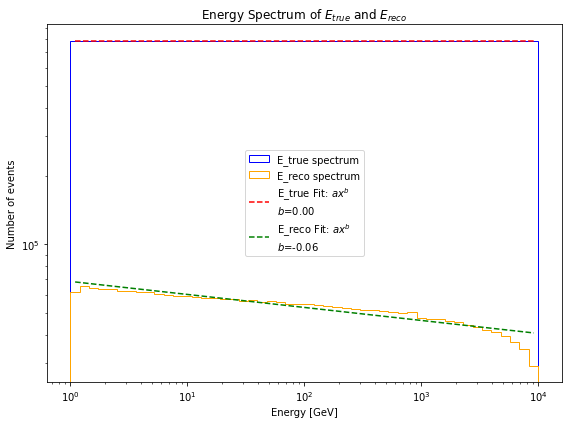

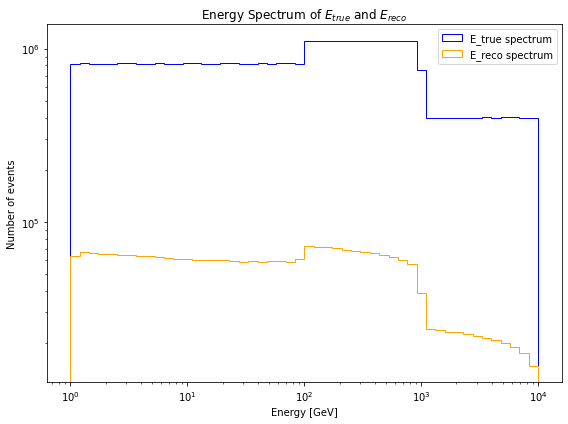

In [10]:
from scipy.optimize import curve_fit

n_bins = 50
E_bins_edge_HET_ = np.logspace(np.log10(Emin), np.log10(Emax_HET), n_bins + 1)

plt.figure(figsize=(8, 6))
# Plot histogram for E_true
counts, bins, _ = plt.hist(df['E_true'], bins=E_bins_edge_HET_, histtype='step', color='blue', label='E_true spectrum', weights=df['weight'])
# Plot histogram for E_reco
counts_reco, bins_reco, _ = plt.hist(df['E_reco'], bins=E_bins_edge_HET_, histtype='step', color='orange', label='E_reco spectrum', weights=df['weight'])

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Energy [GeV]')
plt.ylabel('Number of events')
plt.title('Energy Spectrum of $E_{true}$ and $E_{reco}$')

# Fit the bin centers with a power law (for E_true)
bin_centers = 0.5 * (bins[:-1] + bins[1:])
mask = counts > 0
x = bin_centers[mask]
y = counts[mask]

def power_law(x, a, b):
    return a * x**b

popt, pcov = curve_fit(power_law, x, y)
a_fit, b_fit = popt

# Plot the fit for E_true
x_fit = np.logspace(np.log10(x.min()), np.log10(x.max()), 200)
plt.plot(x_fit, power_law(x_fit, *popt), 'r--', label=f'E_true Fit: $a x^b$\n$b$={b_fit:.2f}')

# Fit the bin centers with a power law (for E_reco), ignoring the first three bins
bin_centers_reco = 0.5 * (bins_reco[:-1] + bins_reco[1:])
mask_reco = counts_reco > 0
# Ignore the first three bins
x_reco = bin_centers_reco[mask_reco][5:]
y_reco = counts_reco[mask_reco][5:]

popt_reco, pcov_reco = curve_fit(power_law, x_reco, y_reco)
a_fit_reco, b_fit_reco = popt_reco

# Plot the fit for E_reco
plt.plot(x_fit, power_law(x_fit, *popt_reco), 'g--', label=f'E_reco Fit: $a x^b$\n$b$={b_fit_reco:.2f}')

plt.legend()
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 6))
# Plot histogram for E_true
counts, bins, _ = plt.hist(df['E_true'], bins=E_bins_edge_HET_, histtype='step', color='blue', label='E_true spectrum')
# Plot histogram for E_reco
counts_reco, bins_reco, _ = plt.hist(df['E_reco'], bins=E_bins_edge_HET_, histtype='step', color='orange', label='E_reco spectrum')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Energy [GeV]')
plt.ylabel('Number of events')
plt.title('Energy Spectrum of $E_{true}$ and $E_{reco}$')
plt.legend()
plt.tight_layout()
plt.show()

Creating plot 1...
Creating plot 2...
Creating plot 3...
Creating plot 4...


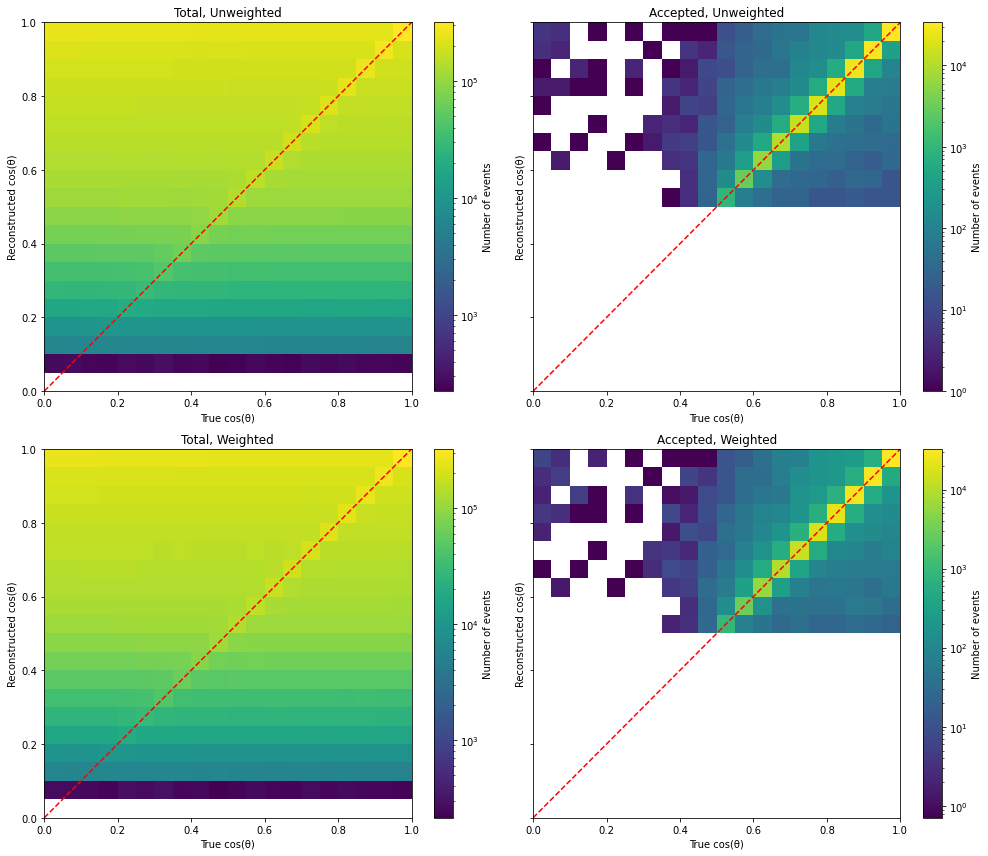

Plotting completed successfully!


In [11]:
from matplotlib.colors import LogNorm

try:
    fig, axs = plt.subplots(2, 2, figsize=(14, 12), sharey=True)
    
    # Top left - Total, Unweighted  
    print("Creating plot 1...")
    h1 = axs[0,0].hist2d(df['cosTheta'], df['cosThetaSTK'], bins=theta_bins_edge, cmap='viridis', norm=LogNorm())
    fig.colorbar(h1[3], ax=axs[0,0], label="Number of events")
    axs[0,0].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[0,0].set_xlabel('True cos(θ)')
    axs[0,0].set_ylabel('Reconstructed cos(θ)')
    axs[0,0].set_title('Total, Unweighted')
    
    # Bottom left - Total, Weighted
    print("Creating plot 2...")
    h2 = axs[1,0].hist2d(df['cosTheta'], df['cosThetaSTK'], bins=theta_bins_edge, cmap='viridis', weights=df['weight'], norm=LogNorm())
    fig.colorbar(h2[3], ax=axs[1,0], label="Number of events")
    axs[1,0].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[1,0].set_xlabel('True cos(θ)')
    axs[1,0].set_ylabel('Reconstructed cos(θ)')
    axs[1,0].set_title('Total, Weighted')
    
    # Top right - Accepted, Unweighted
    print("Creating plot 3...")
    h3 = axs[0,1].hist2d(dfHET['cosTheta'], dfHET['cosThetaSTK'], bins=theta_bins_edge, cmap='viridis', norm=LogNorm())
    fig.colorbar(h3[3], ax=axs[0,1], label="Number of events")
    axs[0,1].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[0,1].set_xlabel('True cos(θ)')
    axs[0,1].set_ylabel('Reconstructed cos(θ)')
    axs[0,1].set_title('Accepted, Unweighted')
    
    # Bottom right - Accepted, Weighted  
    print("Creating plot 4...")
    h4 = axs[1,1].hist2d(dfHET['cosTheta'], dfHET['cosThetaSTK'], bins=theta_bins_edge, cmap='viridis', weights=dfHET['weight'], norm=LogNorm())
    fig.colorbar(h4[3], ax=axs[1,1], label="Number of events")
    axs[1,1].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[1,1].set_xlabel('True cos(θ)')
    axs[1,1].set_ylabel('Reconstructed cos(θ)')
    axs[1,1].set_title('Accepted, Weighted')
    
    plt.tight_layout()
    plt.show()
    print("Plotting completed successfully!")
    
except Exception as e:
    print(f"Error occurred: {e}")
    import traceback
    traceback.print_exc()


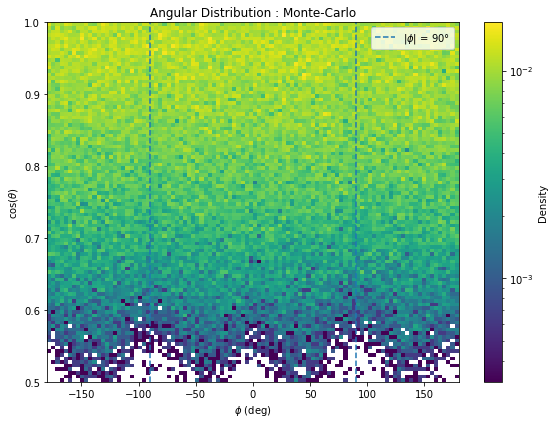

In [12]:

from matplotlib.colors import LogNorm

# Plot a 2D histogram: x = phi_BestSTK, y = cos(theta_BestSTK)
fig, ax = plt.subplots(figsize=(8, 6))
h = ax.hist2d(
    np.rad2deg(dfHET["tt_phi"]), 
    np.cos(dfHET["theta_True"]), 
    bins=[100, 100], 
    range=[[-180, 180], [0.5, 1]],
    cmap='viridis',
    norm=LogNorm(),
    density=True
)
ax.axvline(90, ls='--', label = "$|\phi|$ = 90°")
ax.axvline(-90, ls='--')
ax.set_xlabel("$\phi$ (deg)")
ax.set_ylabel("$\cos(\\theta)$")
ax.set_title("Angular Distribution : Monte-Carlo")
plt.colorbar(h[3], ax=ax, label='Density')
plt.legend()
plt.tight_layout()
fig.savefig(figPath + "MC_phi_vs_costheta_2dhist.png", dpi=400)
plt.show()

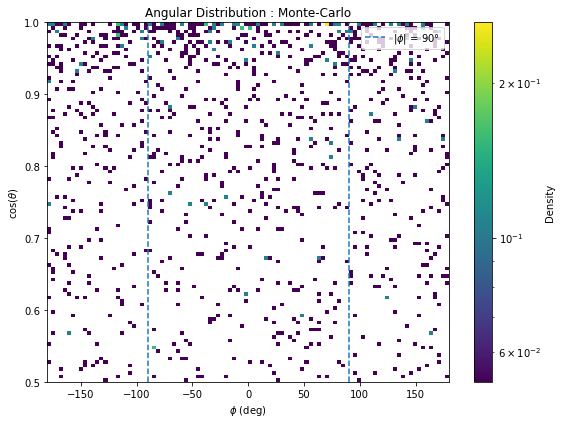

In [13]:

from matplotlib.colors import LogNorm

# Plot a 2D histogram: x = phi_BestSTK, y = cos(theta_BestSTK)
fig, ax = plt.subplots(figsize=(8, 6))
h = ax.hist2d(
    np.rad2deg(dfHET["phi_BestSTK"]), 
    np.cos(dfHET["theta_BestSTK"]), 
    bins=[100, 100], 
    range=[[-180, 180], [0.5, 1]],
    cmap='viridis',
    norm=LogNorm(),
    density=True
)
ax.axvline(90, ls='--', label = "$|\phi|$ = 90°")
ax.axvline(-90, ls='--')
ax.set_xlabel("$\phi$ (deg)")
ax.set_ylabel("$\cos(\\theta)$")
ax.set_title("Angular Distribution : Monte-Carlo")
plt.colorbar(h[3], ax=ax, label='Density')
plt.legend()
plt.tight_layout()
fig.savefig(figPath + "MC_phi_vs_costheta_2dhist.png", dpi=400)
plt.show()

### Interpretation 
Total plus diffus : changer de theta_true à theta_reco peut spread des évènements sous le threshold de 60° ? 

Creating plot 1...
Creating plot 2...
Creating plot 3...
Creating plot 4...


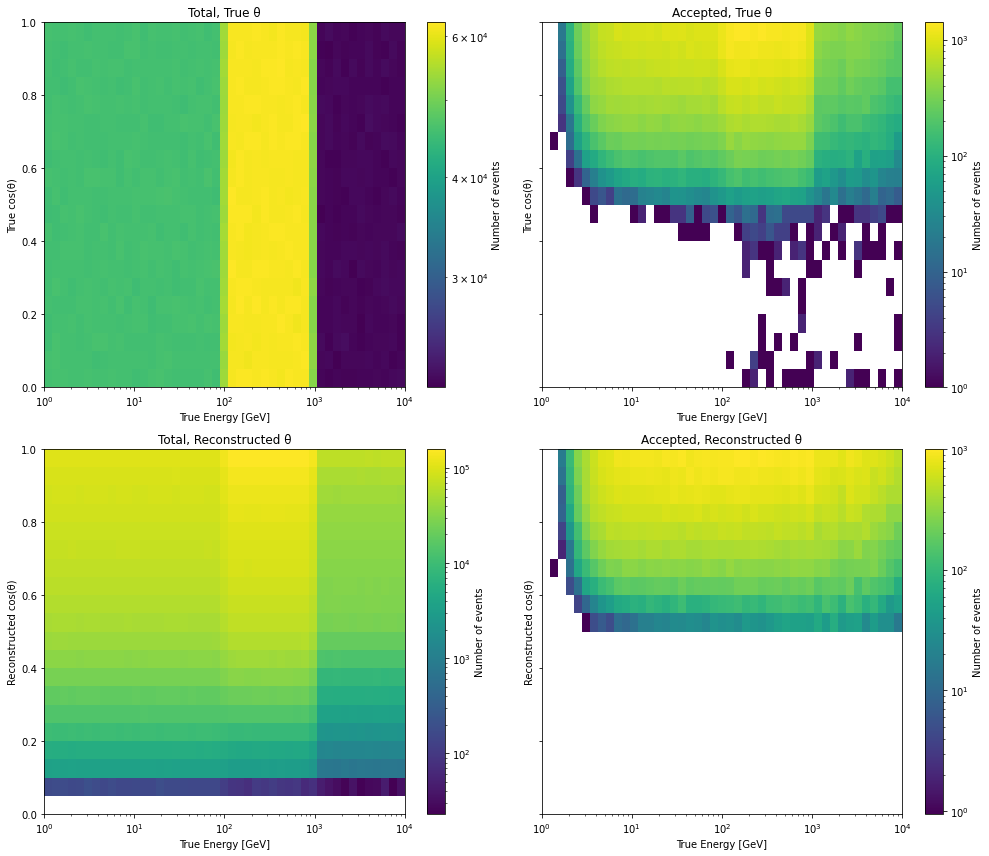

Plotting completed successfully!


In [14]:
from matplotlib.colors import LogNorm

try:
    fig, axs = plt.subplots(2, 2, figsize=(14, 12), sharey=True)
    
    # Top left - Total, Unweighted  
    print("Creating plot 1...")
    h1 = axs[0,0].hist2d(df['E_true'], df['cosTheta'], bins=[E_bins_edge_HET, theta_bins_edge], cmap='viridis', norm=LogNorm())
    fig.colorbar(h1[3], ax=axs[0,0], label="Number of events")
    axs[0,0].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[0,0].set_xlabel('True Energy [GeV]')
    axs[0,0].set_xscale('log')
    axs[0,0].set_ylabel('True cos(θ)')
    axs[0,0].set_title('Total, True θ')
    
    # Bottom left - Total, Weighted
    print("Creating plot 2...")
    h2 = axs[1,0].hist2d(df['E_true'], df['cosThetaSTK'], bins=[E_bins_edge_HET, theta_bins_edge], cmap='viridis', norm=LogNorm())
    fig.colorbar(h2[3], ax=axs[1,0], label="Number of events")
    axs[1,0].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[1,0].set_xlabel('True Energy [GeV]')
    axs[1,0].set_xscale('log')
    axs[1,0].set_ylabel('Reconstructed cos(θ)')
    axs[1,0].set_title('Total, Reconstructed θ')
    
    # Top right - Accepted, Unweighted
    print("Creating plot 3...")
    h3 = axs[0,1].hist2d(dfHET['E_true'], dfHET['cosTheta'], bins=[E_bins_edge_HET, theta_bins_edge], cmap='viridis', norm=LogNorm())
    fig.colorbar(h3[3], ax=axs[0,1], label="Number of events")
    axs[0,1].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[0,1].set_xlabel('True Energy [GeV]')
    axs[0,1].set_xscale('log')
    axs[0,1].set_ylabel('True cos(θ)')
    axs[0,1].set_title('Accepted, True θ')
    
    # Bottom right - Accepted, Weighted  
    print("Creating plot 4...")
    h4 = axs[1,1].hist2d(dfHET['E_true'], dfHET['cosThetaSTK'], bins=[E_bins_edge_HET, theta_bins_edge], cmap='viridis', weights=dfHET['weight'], norm=LogNorm())
    fig.colorbar(h4[3], ax=axs[1,1], label="Number of events")
    axs[1,1].plot([cos_theta_min, cos_theta_max], [cos_theta_min, cos_theta_max], 'r--', label='Perfect reconstruction')
    axs[1,1].set_xlabel('True Energy [GeV]')
    axs[1,1].set_xscale('log')
    axs[1,1].set_ylabel('Reconstructed cos(θ)')
    axs[1,1].set_title('Accepted, Reconstructed θ')
    
    plt.tight_layout()
    plt.show()
    print("Plotting completed successfully!")
    
except Exception as e:
    print(f"Error occurred: {e}")
    import traceback
    traceback.print_exc()


Creating plot 1...
Creating plot 2...
Creating plot 3...
Creating plot 4...


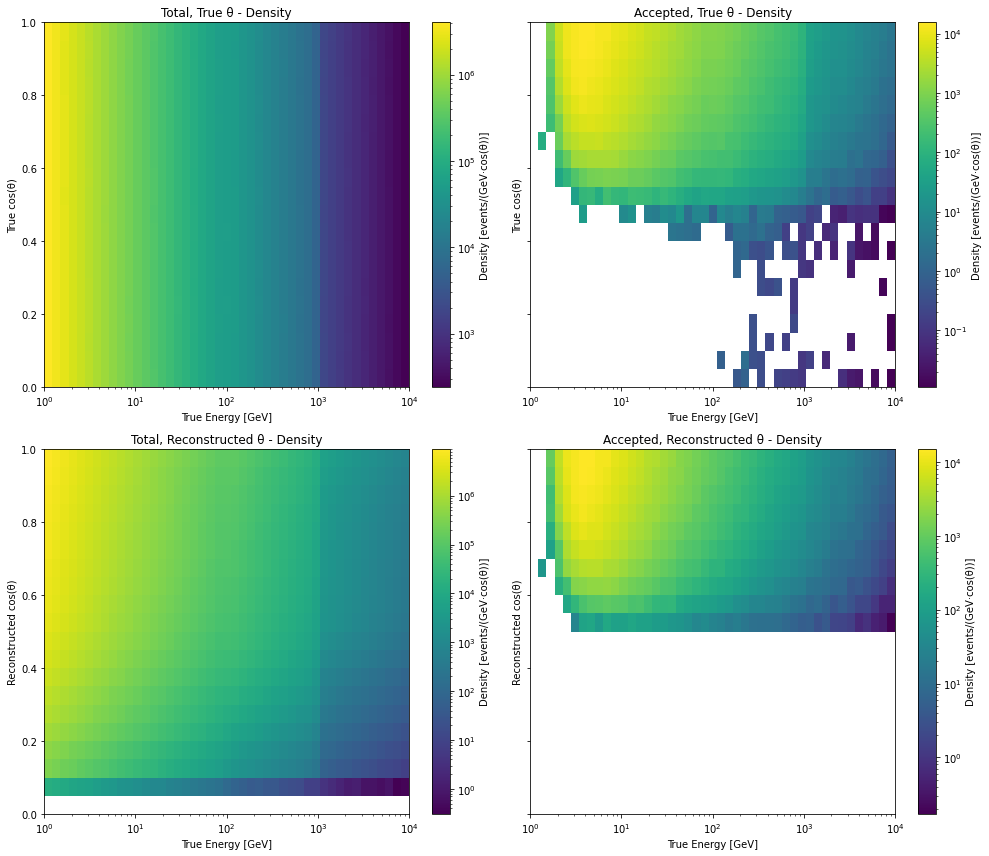

Plotting completed successfully!


In [15]:

# Calculate bin widths for normalization
E_bin_widths = E_bins_edge_HET[1:] - E_bins_edge_HET[:-1]
theta_bin_widths = theta_bins_edge[1:] - theta_bins_edge[:-1]

# Create 2D bin area matrix for normalization
E_widths_2d, theta_widths_2d = np.meshgrid(E_bin_widths, theta_bin_widths, indexing='ij')
bin_areas = E_widths_2d * theta_widths_2d

def normalize_hist2d_to_density(counts, E_bin_widths, theta_bin_widths):
    """Convert counts to density by normalizing by bin areas"""
    E_widths_2d, theta_widths_2d = np.meshgrid(E_bin_widths, theta_bin_widths, indexing='ij')
    bin_areas = E_widths_2d * theta_widths_2d
    # Avoid division by zero
    density = np.divide(counts, bin_areas, out=np.zeros_like(counts), where=bin_areas!=0)
    return density

try:
    fig, axs = plt.subplots(2, 2, figsize=(14, 12), sharey=True)
    
    # Top left - Total, Unweighted  
    print("Creating plot 1...")
    counts1, _, _, _ = axs[0,0].hist2d(df['E_true'], df['cosTheta'], 
                                       bins=[E_bins_edge_HET, theta_bins_edge], 
                                       cmap='viridis', norm=LogNorm())
    # Clear the plot and create density version
    axs[0,0].clear()
    density1 = normalize_hist2d_to_density(counts1, E_bin_widths, theta_bin_widths)
    # Mask zeros for log scale
    density1_masked = np.ma.masked_where(density1 <= 0, density1)
    im1 = axs[0,0].pcolormesh(E_bins_edge_HET, theta_bins_edge, density1_masked.T, 
                              cmap='viridis', norm=LogNorm())
    fig.colorbar(im1, ax=axs[0,0], label="Density [events/(GeV·cos(θ))]")
    axs[0,0].set_xlabel('True Energy [GeV]')
    axs[0,0].set_xscale('log')
    axs[0,0].set_ylabel('True cos(θ)')
    axs[0,0].set_title('Total, True θ - Density')
    
    # Bottom left - Total, Weighted
    print("Creating plot 2...")
    counts2, _, _, _ = axs[1,0].hist2d(df['E_true'], df['cosThetaSTK'], 
                                       bins=[E_bins_edge_HET, theta_bins_edge], 
                                       cmap='viridis', norm=LogNorm())
    axs[1,0].clear()
    density2 = normalize_hist2d_to_density(counts2, E_bin_widths, theta_bin_widths)
    density2_masked = np.ma.masked_where(density2 <= 0, density2)
    im2 = axs[1,0].pcolormesh(E_bins_edge_HET, theta_bins_edge, density2_masked.T, 
                              cmap='viridis', norm=LogNorm())
    fig.colorbar(im2, ax=axs[1,0], label="Density [events/(GeV·cos(θ))]")
    axs[1,0].set_xlabel('True Energy [GeV]')
    axs[1,0].set_xscale('log')
    axs[1,0].set_ylabel('Reconstructed cos(θ)')
    axs[1,0].set_title('Total, Reconstructed θ - Density')
    
    # Top right - Accepted, Unweighted
    print("Creating plot 3...")
    counts3, _, _, _ = axs[0,1].hist2d(dfHET['E_true'], dfHET['cosTheta'], 
                                       bins=[E_bins_edge_HET, theta_bins_edge], 
                                       cmap='viridis', norm=LogNorm())
    axs[0,1].clear()
    density3 = normalize_hist2d_to_density(counts3, E_bin_widths, theta_bin_widths)
    density3_masked = np.ma.masked_where(density3 <= 0, density3)
    im3 = axs[0,1].pcolormesh(E_bins_edge_HET, theta_bins_edge, density3_masked.T, 
                              cmap='viridis', norm=LogNorm())
    fig.colorbar(im3, ax=axs[0,1], label="Density [events/(GeV·cos(θ))]")
    axs[0,1].set_xlabel('True Energy [GeV]')
    axs[0,1].set_xscale('log')
    axs[0,1].set_ylabel('True cos(θ)')
    axs[0,1].set_title('Accepted, True θ - Density')
    
    # Bottom right - Accepted, Weighted  
    print("Creating plot 4...")
    counts4, _, _, _ = axs[1,1].hist2d(dfHET['E_true'], dfHET['cosThetaSTK'], 
                                       bins=[E_bins_edge_HET, theta_bins_edge], 
                                       weights=dfHET['weight'], cmap='viridis', norm=LogNorm())
    axs[1,1].clear()
    density4 = normalize_hist2d_to_density(counts4, E_bin_widths, theta_bin_widths)
    density4_masked = np.ma.masked_where(density4 <= 0, density4)
    im4 = axs[1,1].pcolormesh(E_bins_edge_HET, theta_bins_edge, density4_masked.T, 
                              cmap='viridis', norm=LogNorm())
    fig.colorbar(im4, ax=axs[1,1], label="Density [events/(GeV·cos(θ))]")
    axs[1,1].set_xlabel('True Energy [GeV]')
    axs[1,1].set_xscale('log')
    axs[1,1].set_ylabel('Reconstructed cos(θ)')
    axs[1,1].set_title('Accepted, Reconstructed θ - Density')
    
    plt.tight_layout()
    plt.show()
    print("Plotting completed successfully!")
    
except Exception as e:
    print(f"Error occurred: {e}")
    import traceback
    traceback.print_exc()

### Angular distribution, Unweighted

Creating plot 1...
Creating plot 2...


Creating plot 3...
Creating plot 4...


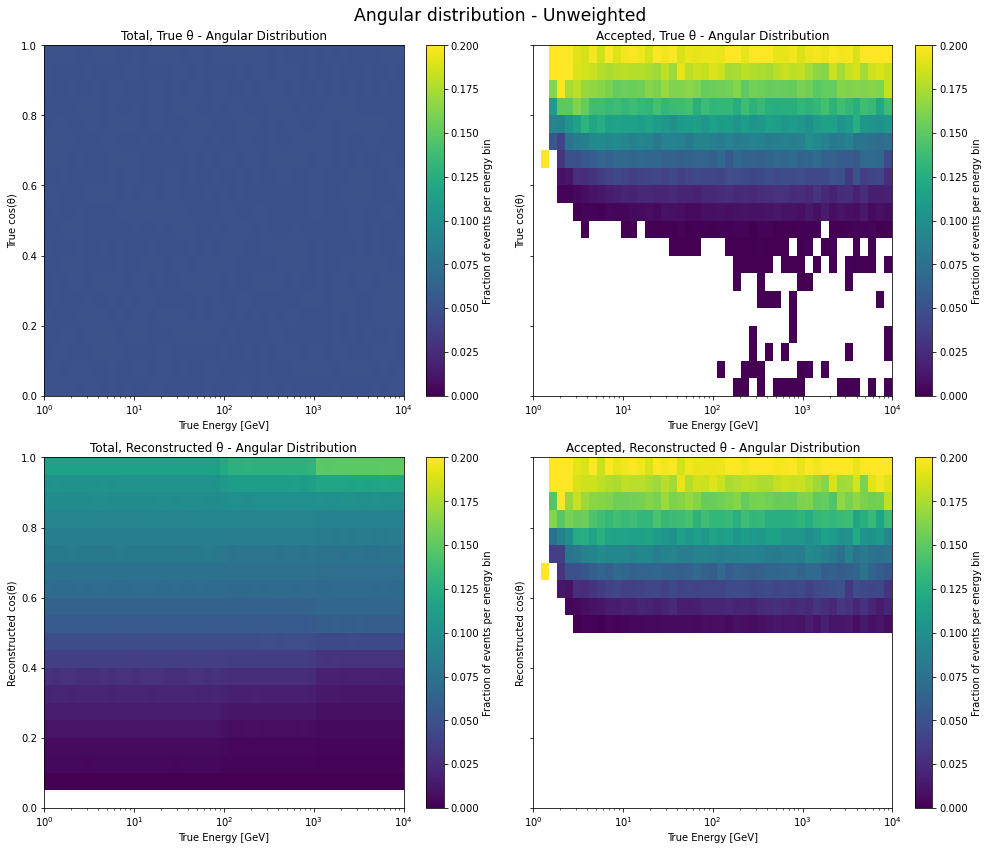

Plotting completed successfully!
Example: Energy bin 10 normalization check:
Sum of normalized counts in energy bin 10: 1.000


In [16]:
def normalize_by_energy_bin(counts):
    """Normalize each energy bin (column) by its total count"""
    # Sum over theta axis (axis=1) to get total counts per energy bin
    energy_totals = np.sum(counts, axis=1, keepdims=True)
    # Avoid division by zero
    normalized = np.divide(counts, energy_totals, out=np.zeros_like(counts), where=energy_totals!=0)
    return normalized

vmin = 0
vmax = 0.2

try:
    fig, axs = plt.subplots(2, 2, figsize=(14, 12), sharey=True)
    
    # Top left - Total, True theta
    print("Creating plot 1...")
    counts1, _, _ = np.histogram2d(df['E_true'], df['cosTheta'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge])
    normalized1 = normalize_by_energy_bin(counts1)
    # Mask zeros for better visualization
    normalized1_masked = np.ma.masked_where(normalized1 <= 0, normalized1)
    im1 = axs[0,0].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized1_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im1, ax=axs[0,0], label="Fraction of events per energy bin")
    axs[0,0].set_xlabel('True Energy [GeV]')
    axs[0,0].set_xscale('log')
    axs[0,0].set_ylabel('True cos(θ)')
    axs[0,0].set_title('Total, True θ - Angular Distribution')
    
    # Bottom left - Total, Reconstructed theta
    print("Creating plot 2...")
    counts2, _, _ = np.histogram2d(df['E_true'], df['cosThetaSTK'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge])
    normalized2 = normalize_by_energy_bin(counts2)
    normalized2_masked = np.ma.masked_where(normalized2 <= 0, normalized2)
    im2 = axs[1,0].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized2_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im2, ax=axs[1,0], label="Fraction of events per energy bin")
    axs[1,0].set_xlabel('True Energy [GeV]')
    axs[1,0].set_xscale('log')
    axs[1,0].set_ylabel('Reconstructed cos(θ)')
    axs[1,0].set_title('Total, Reconstructed θ - Angular Distribution')
    
    # Top right - Accepted, True theta
    print("Creating plot 3...")
    counts3, _, _ = np.histogram2d(dfHET['E_true'], dfHET['cosTheta'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge])
    normalized3 = normalize_by_energy_bin(counts3)
    normalized3_masked = np.ma.masked_where(normalized3 <= 0, normalized3)
    im3 = axs[0,1].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized3_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im3, ax=axs[0,1], label="Fraction of events per energy bin")
    axs[0,1].set_xlabel('True Energy [GeV]')
    axs[0,1].set_xscale('log')
    axs[0,1].set_ylabel('True cos(θ)')
    axs[0,1].set_title('Accepted, True θ - Angular Distribution')
    
    # Bottom right - Accepted, Weighted, Reconstructed theta
    print("Creating plot 4...")
    counts4, _, _ = np.histogram2d(dfHET['E_true'], dfHET['cosThetaSTK'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge])
    normalized4 = normalize_by_energy_bin(counts4)
    normalized4_masked = np.ma.masked_where(normalized4 <= 0, normalized4)
    im4 = axs[1,1].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized4_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im4, ax=axs[1,1], label="Fraction of events per energy bin")
    axs[1,1].set_xlabel('True Energy [GeV]')
    axs[1,1].set_xscale('log')
    axs[1,1].set_ylabel('Reconstructed cos(θ)')
    axs[1,1].set_title('Accepted, Reconstructed θ - Angular Distribution')

    fig.suptitle("Angular distribution - Unweighted", size='xx-large')
    
    plt.tight_layout()
    plt.show()
    print("Plotting completed successfully!")
    
    # Optional: Print some statistics
    print(f"Example: Energy bin 10 normalization check:")
    print(f"Sum of normalized counts in energy bin 10: {np.sum(normalized1[10, :]):.3f}")
    
except Exception as e:
    print(f"Error occurred: {e}")
    import traceback
    traceback.print_exc()

Creating plot 1...


Creating plot 2...
Creating plot 3...
Creating plot 4...


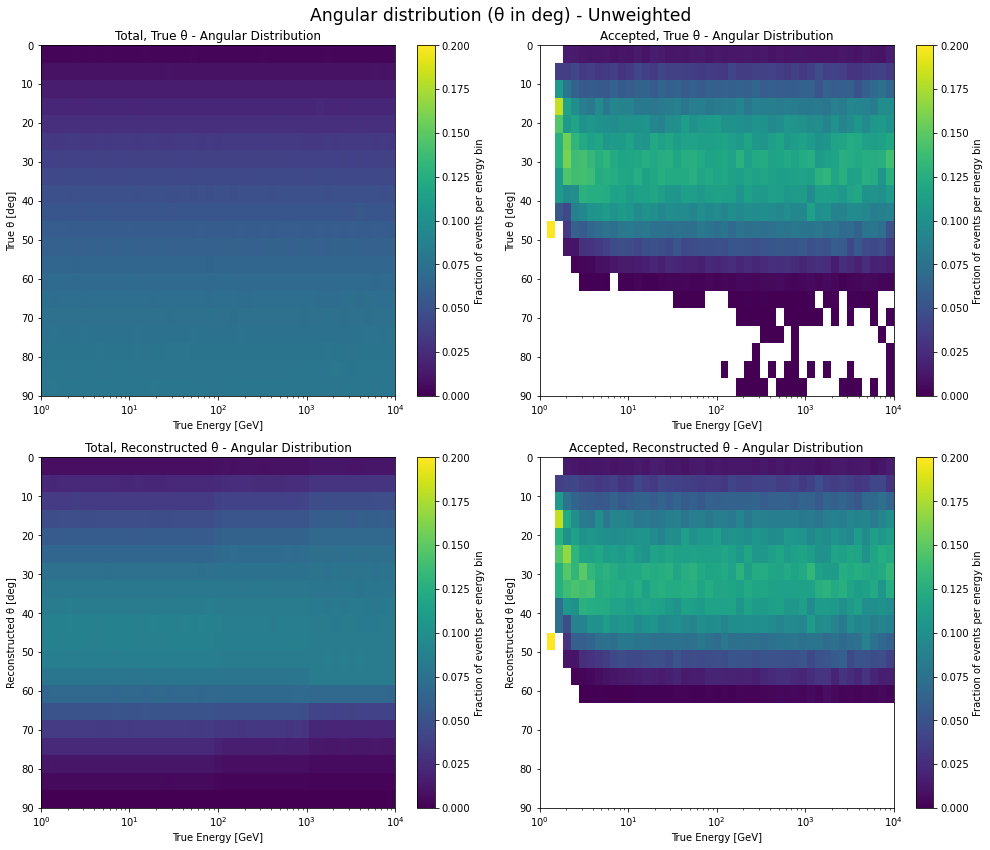

Plotting completed successfully!


In [17]:
def normalize_by_energy_bin(counts):
    """Normalize each energy bin (column) by its total count"""
    energy_totals = np.sum(counts, axis=1, keepdims=True)
    normalized = np.divide(counts, energy_totals, out=np.zeros_like(counts), where=energy_totals!=0)
    return normalized

# Define theta bins in degrees
theta_min_deg = 0
theta_max_deg = 90
n_theta_bins_deg = 20
theta_bins_edge_deg = np.linspace(theta_min_deg, theta_max_deg, n_theta_bins_deg + 1)

vmin = 0
vmax = 0.2

try:
    fig, axs = plt.subplots(2, 2, figsize=(14, 12), sharey=False)

    # Top left - Total, True theta
    print("Creating plot 1...")
    counts1, _, _ = np.histogram2d(df['E_true'], df['theta_True_deg'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg])
    normalized1 = normalize_by_energy_bin(counts1)
    normalized1_masked = np.ma.masked_where(normalized1 <= 0, normalized1)
    im1 = axs[0,0].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized1_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[0,0].invert_yaxis()
    fig.colorbar(im1, ax=axs[0,0], label="Fraction of events per energy bin")
    axs[0,0].set_xlabel('True Energy [GeV]')
    axs[0,0].set_xscale('log')
    axs[0,0].set_ylabel('True θ [deg]')
    axs[0,0].set_title('Total, True θ - Angular Distribution')
    

    # Bottom left - Total, Reconstructed theta
    print("Creating plot 2...")
    counts2, _, _ = np.histogram2d(df['E_true'], df['theta_BestSTK'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg])
    normalized2 = normalize_by_energy_bin(counts2)
    normalized2_masked = np.ma.masked_where(normalized2 <= 0, normalized2)
    im2 = axs[1,0].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized2_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[1,0].invert_yaxis()
    fig.colorbar(im2, ax=axs[1,0], label="Fraction of events per energy bin")
    axs[1,0].set_xlabel('True Energy [GeV]')
    axs[1,0].set_xscale('log')
    axs[1,0].set_ylabel('Reconstructed θ [deg]')
    axs[1,0].set_title('Total, Reconstructed θ - Angular Distribution')
    

    # Top right - Accepted, True theta
    print("Creating plot 3...")
    counts3, _, _ = np.histogram2d(dfHET['E_true'], dfHET['theta_True_deg'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg])
    normalized3 = normalize_by_energy_bin(counts3)
    normalized3_masked = np.ma.masked_where(normalized3 <= 0, normalized3)
    im3 = axs[0,1].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized3_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[0,1].invert_yaxis()
    fig.colorbar(im3, ax=axs[0,1], label="Fraction of events per energy bin")
    axs[0,1].set_xlabel('True Energy [GeV]')
    axs[0,1].set_xscale('log')
    axs[0,1].set_ylabel('True θ [deg]')
    axs[0,1].set_title('Accepted, True θ - Angular Distribution')
    

    # Bottom right - Accepted, Reconstructed theta
    print("Creating plot 4...")
    counts4, _, _ = np.histogram2d(dfHET['E_true'], dfHET['theta_BestSTK'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg])
    normalized4 = normalize_by_energy_bin(counts4)
    normalized4_masked = np.ma.masked_where(normalized4 <= 0, normalized4)
    im4 = axs[1,1].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized4_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[1,1].invert_yaxis()
    fig.colorbar(im4, ax=axs[1,1], label="Fraction of events per energy bin")
    axs[1,1].set_xlabel('True Energy [GeV]')
    axs[1,1].set_xscale('log')
    axs[1,1].set_ylabel('Reconstructed θ [deg]')
    axs[1,1].set_title('Accepted, Reconstructed θ - Angular Distribution')
    

    fig.suptitle("Angular distribution (θ in deg) - Unweighted", size='xx-large')

    plt.tight_layout()
    plt.show()
    print("Plotting completed successfully!")

except Exception as e:
    print(f"Error occurred: {e}")
    traceback.print_exc()

### Angular distribution , Weighted

Creating plot 1...
Creating plot 2...
Creating plot 3...
Creating plot 4...


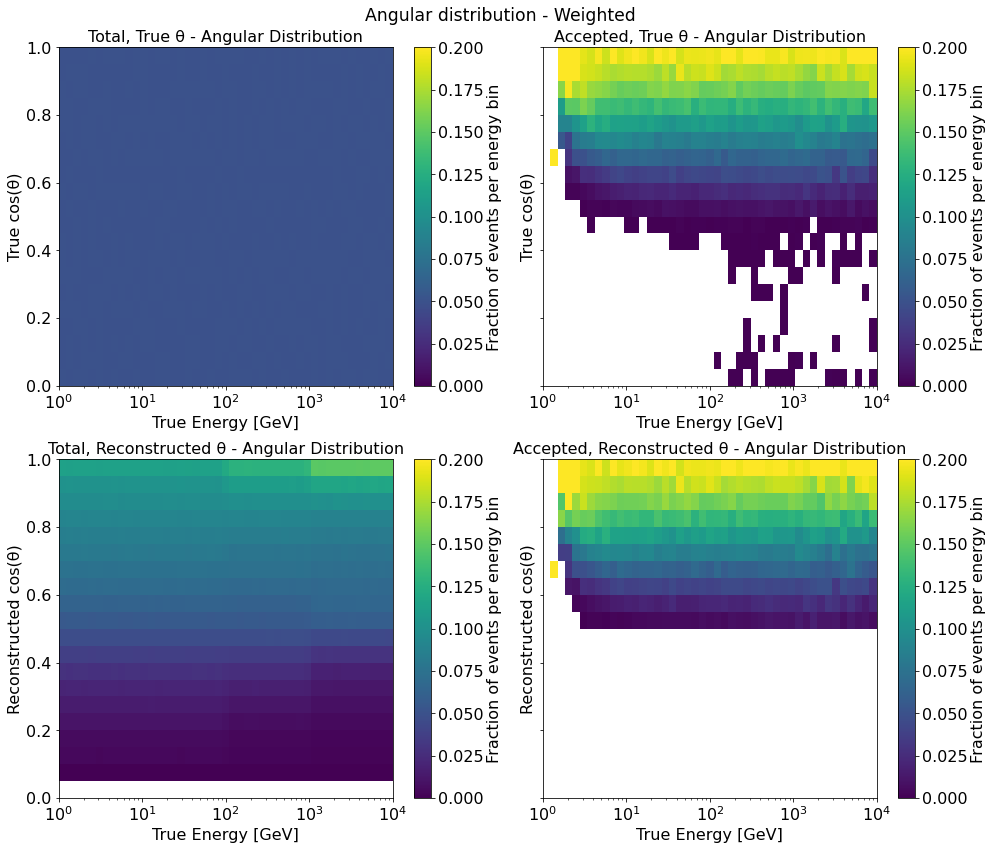

Plotting completed successfully!
Example: Energy bin 10 normalization check:
Sum of normalized counts in energy bin 10: 1.000


In [21]:
def normalize_by_energy_bin(counts):
    """Normalize each energy bin (column) by its total count"""
    # Sum over theta axis (axis=1) to get total counts per energy bin
    energy_totals = np.sum(counts, axis=1, keepdims=True)
    # Avoid division by zero
    normalized = np.divide(counts, energy_totals, out=np.zeros_like(counts), where=energy_totals!=0)
    return normalized

vmin = 0
vmax = 0.2

try:
    fig, axs = plt.subplots(2, 2, figsize=(14, 12), sharey=True)
    
    # Top left - Total, True theta
    print("Creating plot 1...")
    counts1, _, _ = np.histogram2d(df['E_true'], df['cosTheta'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge], weights=df['weight'])
    normalized1 = normalize_by_energy_bin(counts1)
    # Mask zeros for better visualization
    normalized1_masked = np.ma.masked_where(normalized1 <= 0, normalized1)
    im1 = axs[0,0].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized1_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im1, ax=axs[0,0], label="Fraction of events per energy bin")
    axs[0,0].set_xlabel('True Energy [GeV]')
    axs[0,0].set_xscale('log')
    axs[0,0].set_ylabel('True cos(θ)')
    axs[0,0].set_title('Total, True θ - Angular Distribution')
    
    # Bottom left - Total, Reconstructed theta
    print("Creating plot 2...")
    counts2, _, _ = np.histogram2d(df['E_true'], df['cosThetaSTK'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge], weights=df['weight'])
    normalized2 = normalize_by_energy_bin(counts2)
    normalized2_masked = np.ma.masked_where(normalized2 <= 0, normalized2)
    im2 = axs[1,0].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized2_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im2, ax=axs[1,0], label="Fraction of events per energy bin")
    axs[1,0].set_xlabel('True Energy [GeV]')
    axs[1,0].set_xscale('log')
    axs[1,0].set_ylabel('Reconstructed cos(θ)')
    axs[1,0].set_title('Total, Reconstructed θ - Angular Distribution')
    
    # Top right - Accepted, True theta
    print("Creating plot 3...")
    counts3, _, _ = np.histogram2d(dfHET['E_true'], dfHET['cosTheta'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge], weights=dfHET['weight'])
    normalized3 = normalize_by_energy_bin(counts3)
    normalized3_masked = np.ma.masked_where(normalized3 <= 0, normalized3)
    im3 = axs[0,1].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized3_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im3, ax=axs[0,1], label="Fraction of events per energy bin")
    axs[0,1].set_xlabel('True Energy [GeV]')
    axs[0,1].set_xscale('log')
    axs[0,1].set_ylabel('True cos(θ)')
    axs[0,1].set_title('Accepted, True θ - Angular Distribution')
    
    # Bottom right - Accepted, Weighted, Reconstructed theta
    print("Creating plot 4...")
    counts4, _, _ = np.histogram2d(dfHET['E_true'], dfHET['cosThetaSTK'], 
                                   bins=[E_bins_edge_HET, theta_bins_edge], 
                                   weights=dfHET['weight'])
    normalized4 = normalize_by_energy_bin(counts4)
    normalized4_masked = np.ma.masked_where(normalized4 <= 0, normalized4)
    im4 = axs[1,1].pcolormesh(E_bins_edge_HET, theta_bins_edge, normalized4_masked.T, 
                              cmap='viridis', vmin=vmin, vmax=vmax)
    fig.colorbar(im4, ax=axs[1,1], label="Fraction of events per energy bin")

    
    fig.suptitle("Angular distribution - Weighted", size=24)
    axs[1,1].set_xlabel('True Energy [GeV]')
    axs[1,1].set_xscale('log')
    axs[1,1].set_ylabel('Reconstructed cos(θ)')
    axs[1,1].set_title('Accepted, Reconstructed θ - Angular Distribution')
    
    # Increase all fonts in the plots
    for ax in axs.flat:
        ax.tick_params(axis='both', which='major', labelsize=16)
        ax.xaxis.label.set_size(18)
        ax.yaxis.label.set_size(18)
        ax.title.set_size(20)
    for item in fig.findobj():
        if hasattr(item, 'set_fontsize'):
            item.set_fontsize(16)

    fig.suptitle("Angular distribution - Weighted", size='xx-large')

    plt.tight_layout()
    fig.savefig(figPath + "thetaAngularDist.png")
    plt.show()
    print("Plotting completed successfully!")
    
    # Optional: Print some statistics
    print(f"Example: Energy bin 10 normalization check:")
    print(f"Sum of normalized counts in energy bin 10: {np.sum(normalized1[10, :]):.3f}")
    
except Exception as e:
    print(f"Error occurred: {e}")
    import traceback
    traceback.print_exc()

Creating plot 1...


Creating plot 2...
Creating plot 3...
Creating plot 4...


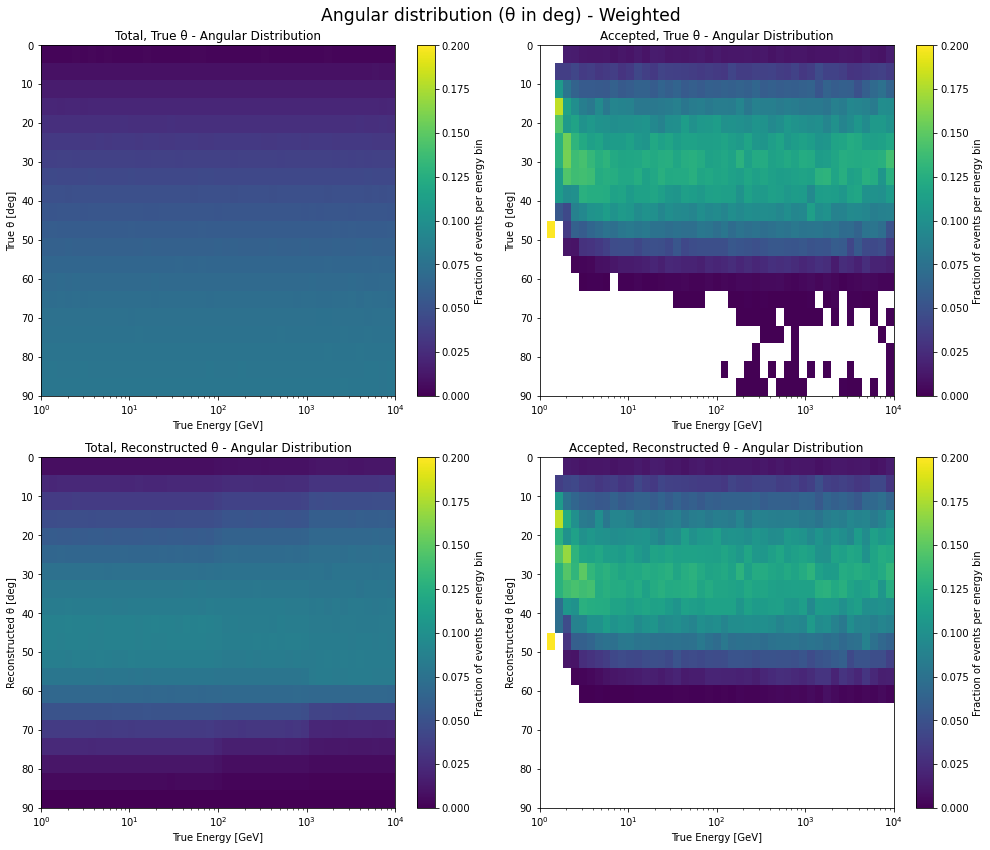

Plotting completed successfully!


In [19]:
def normalize_by_energy_bin(counts):
    """Normalize each energy bin (column) by its total count"""
    energy_totals = np.sum(counts, axis=1, keepdims=True)
    normalized = np.divide(counts, energy_totals, out=np.zeros_like(counts), where=energy_totals!=0)
    return normalized

# Define theta bins in degrees
theta_min_deg = 0
theta_max_deg = 90
n_theta_bins_deg = 20
theta_bins_edge_deg = np.linspace(theta_min_deg, theta_max_deg, n_theta_bins_deg + 1)

vmin = 0
vmax = 0.2

try:
    fig, axs = plt.subplots(2, 2, figsize=(14, 12), sharey=False)

    # Top left - Total, True theta
    print("Creating plot 1...")
    counts1, _, _ = np.histogram2d(df['E_true'], df['theta_True_deg'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg], weights=df['weight'])
    normalized1 = normalize_by_energy_bin(counts1)
    normalized1_masked = np.ma.masked_where(normalized1 <= 0, normalized1)
    im1 = axs[0,0].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized1_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[0,0].invert_yaxis()
    fig.colorbar(im1, ax=axs[0,0], label="Fraction of events per energy bin")
    axs[0,0].set_xlabel('True Energy [GeV]')
    axs[0,0].set_xscale('log')
    axs[0,0].set_ylabel('True θ [deg]')
    axs[0,0].set_title('Total, True θ - Angular Distribution')
    

    # Bottom left - Total, Reconstructed theta
    print("Creating plot 2...")
    counts2, _, _ = np.histogram2d(df['E_true'], df['theta_BestSTK'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg], weights=df['weight'])
    normalized2 = normalize_by_energy_bin(counts2)
    normalized2_masked = np.ma.masked_where(normalized2 <= 0, normalized2)
    im2 = axs[1,0].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized2_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[1,0].invert_yaxis()
    fig.colorbar(im2, ax=axs[1,0], label="Fraction of events per energy bin")
    axs[1,0].set_xlabel('True Energy [GeV]')
    axs[1,0].set_xscale('log')
    axs[1,0].set_ylabel('Reconstructed θ [deg]')
    axs[1,0].set_title('Total, Reconstructed θ - Angular Distribution')
    

    # Top right - Accepted, True theta
    print("Creating plot 3...")
    counts3, _, _ = np.histogram2d(dfHET['E_true'], dfHET['theta_True_deg'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg], weights=dfHET['weight'])
    normalized3 = normalize_by_energy_bin(counts3)
    normalized3_masked = np.ma.masked_where(normalized3 <= 0, normalized3)
    im3 = axs[0,1].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized3_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[0,1].invert_yaxis()
    fig.colorbar(im3, ax=axs[0,1], label="Fraction of events per energy bin")
    axs[0,1].set_xlabel('True Energy [GeV]')
    axs[0,1].set_xscale('log')
    axs[0,1].set_ylabel('True θ [deg]')
    axs[0,1].set_title('Accepted, True θ - Angular Distribution')
    

    # Bottom right - Accepted, Reconstructed theta
    print("Creating plot 4...")
    counts4, _, _ = np.histogram2d(dfHET['E_true'], dfHET['theta_BestSTK'],
                                   bins=[E_bins_edge_HET, theta_bins_edge_deg], weights=dfHET['weight'])
    normalized4 = normalize_by_energy_bin(counts4)
    normalized4_masked = np.ma.masked_where(normalized4 <= 0, normalized4)
    im4 = axs[1,1].pcolormesh(E_bins_edge_HET, theta_bins_edge_deg, normalized4_masked.T,
                              cmap='viridis', vmin=vmin, vmax=vmax)
    axs[1,1].invert_yaxis()
    fig.colorbar(im4, ax=axs[1,1], label="Fraction of events per energy bin")
    axs[1,1].set_xlabel('True Energy [GeV]')
    axs[1,1].set_xscale('log')
    axs[1,1].set_ylabel('Reconstructed θ [deg]')
    axs[1,1].set_title('Accepted, Reconstructed θ - Angular Distribution')
    

    fig.suptitle("Angular distribution (θ in deg) - Weighted", size='xx-large')

    plt.tight_layout()
    plt.show()
    print("Plotting completed successfully!")

except Exception as e:
    print(f"Error occurred: {e}")
    traceback.print_exc()